# Will an asteroid hit Earth? A Sentry risk explorer

**CS85 Project 7.** NASA JPL's **Sentry** system watches every known near-Earth asteroid and lists the ones whose possible future paths include an Earth impact. This notebook explores that list:

1. **The risk table:** which objects are on the list right now, and how risky are they?
2. **The risk map:** impact chance vs. Palermo scale for every object.
3. **How threats disappear:** most objects are removed once more observations pin down their orbit. How fast?
4. **Case study: 2024 YR4,** the asteroid that briefly had a 3% chance of hitting Earth.

All data comes from public NASA JPL APIs (sources at the end). Downloads are saved in `data/` so the notebook only fetches them once.

In [1]:
import json, re
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Work from the repo root whether the notebook runs from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA, PLOTS = ROOT / 'data', ROOT / 'plots'
DATA.mkdir(exist_ok=True); PLOTS.mkdir(exist_ok=True)

API = 'https://ssd-api.jpl.nasa.gov/sentry.api'

def get_json(url, cache_name):
    """Download JSON once, then reuse the saved copy in data/."""
    path = DATA / cache_name
    if not path.exists():
        r = requests.get(url, timeout=60)
        r.raise_for_status()                    # stop with a clear error if the download fails
        path.write_text(r.text)
    return json.loads(path.read_text())

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e3e6ea', 'grid.linewidth': 0.8, 'axes.axisbelow': True})

## 1. The risk table

Each row is one asteroid. Key columns:

- **ip**: cumulative impact probability (all possible impact dates added up).
- **ps_cum**: cumulative **Palermo scale**. It compares the risk with the normal background chance of an impact that size. **0** means "as risky as the background"; every step down (−1, −2, …) is 10× less worrying.
- **diameter**: estimated size in km.
- **range**: the years in which an impact is possible.

In [2]:
sentry = get_json(API, 'sentry_list.json')
df = pd.DataFrame(sentry['data'])
for col in ['ip', 'ps_cum', 'ps_max', 'diameter', 'v_inf', 'h']:
    df[col] = pd.to_numeric(df[col], errors='coerce')     # the API sends numbers as text

print(f"Objects on the Sentry list: {len(df):,}")
print(f"Palermo scale above 0 (more worrying than background): {(df['ps_cum'] > 0).sum()}")
print(f"Impact chance above 1%: {(df['ip'] > 0.01).sum()}")
print(f"Larger than 140 m (big enough to devastate a region): {(df['diameter'] >= 0.14).sum()}")

table = (df.nlargest(10, 'ps_cum')
           [['fullname', 'ps_cum', 'ip', 'diameter', 'range']]
           .rename(columns={'fullname': 'object', 'ps_cum': 'Palermo', 'ip': 'impact chance',
                            'diameter': 'diameter (km)', 'range': 'possible years'}))
table['object'] = table['object'].str.strip()
table['impact chance'] = table['impact chance'].map(lambda p: f"1 in {1/p:,.0f}")
table.reset_index(drop=True)

Objects on the Sentry list: 2,243
Palermo scale above 0 (more worrying than background): 0
Impact chance above 1%: 4
Larger than 140 m (big enough to devastate a region): 23


,object,Palermo,impact chance,diameter (km),possible years
0,29075 (1950 DA),-0.98,"1 in 2,940",1.3000,2880-2880
1,101955 Bennu (1999 RQ36),-1.40,"1 in 1,749",0.4900,2178-2290
2,(2008 JL3),-2.38,"1 in 6,031",0.0290,2027-2122
3,(1979 XB),-2.69,"1 in 1,174,376",0.6600,2056-2113
4,(2000 SG344),-2.76,1 in 365,0.0370,2069-2122
5,(2010 RF12),-2.96,1 in 10,0.0071,2095-2122
6,(2007 FT3),-3.00,"1 in 1,291,265",0.3410,2030-2119
7,(2022 PX1),-3.07,"1 in 309,502",0.1200,2040-2040
8,(2005 QK76),-3.10,"1 in 14,175",0.0310,2030-2059
9,(2021 GX9),-3.18,"1 in 12,162",0.0290,2032-2052


## 2. The risk map

Every dot is one asteroid. Further right means a higher chance of impact; higher up means more worrying overall (Palermo scale). Bigger dots are bigger asteroids. The dashed line at Palermo = 0 is the "normal background risk" level.

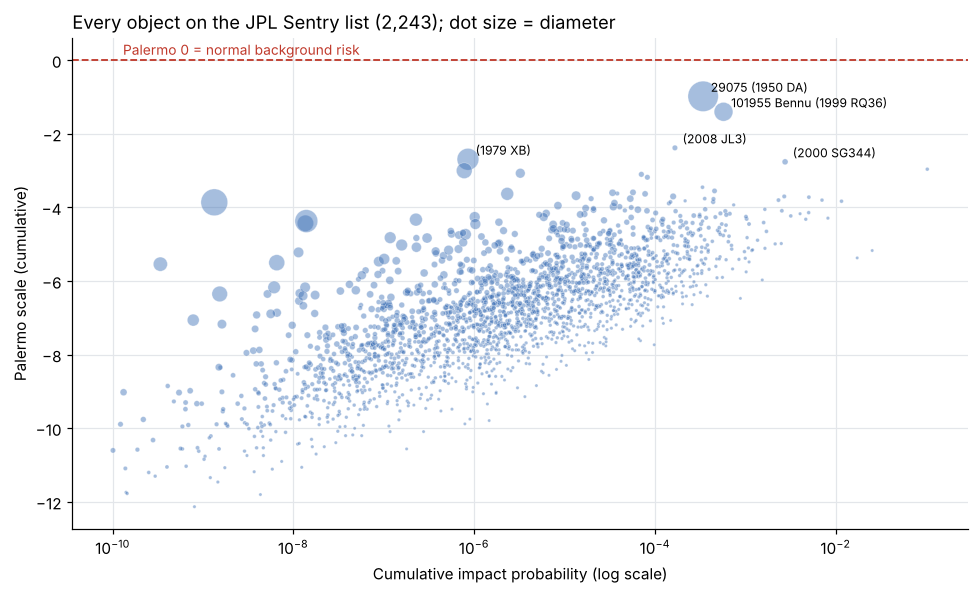

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(df['ip'], df['ps_cum'], s=4 + 300 * df['diameter'].fillna(0),
           color='#3b6fb6', alpha=0.45, edgecolor='white', linewidth=0.4)
ax.axhline(0, color='#c0392b', linestyle='--', linewidth=1.2)
ax.text(1.3e-10, 0.15, 'Palermo 0 = normal background risk', color='#c0392b', fontsize=9)
for _, row in df.nlargest(5, 'ps_cum').iterrows():
    ax.annotate(row['fullname'].strip(), (row['ip'], row['ps_cum']), fontsize=8,
                xytext=(5, 3), textcoords='offset points')
ax.set_xscale('log')
ax.set_xlabel('Cumulative impact probability (log scale)')
ax.set_ylabel('Palermo scale (cumulative)')
ax.set_title(f'Every object on the JPL Sentry list ({len(df):,}); dot size = diameter', loc='left')
fig.tight_layout(); fig.savefig(PLOTS / '07_risk_map.png', dpi=150); plt.show()

## 3. How quickly do "threats" disappear?

Sentry also keeps a list of objects it has **removed**, usually because new observations shrank the orbit's uncertainty until no impact path was left. (`?removed=1` in the API.)

First: how many objects were removed each year?

Objects removed from Sentry since 2002: 3,598


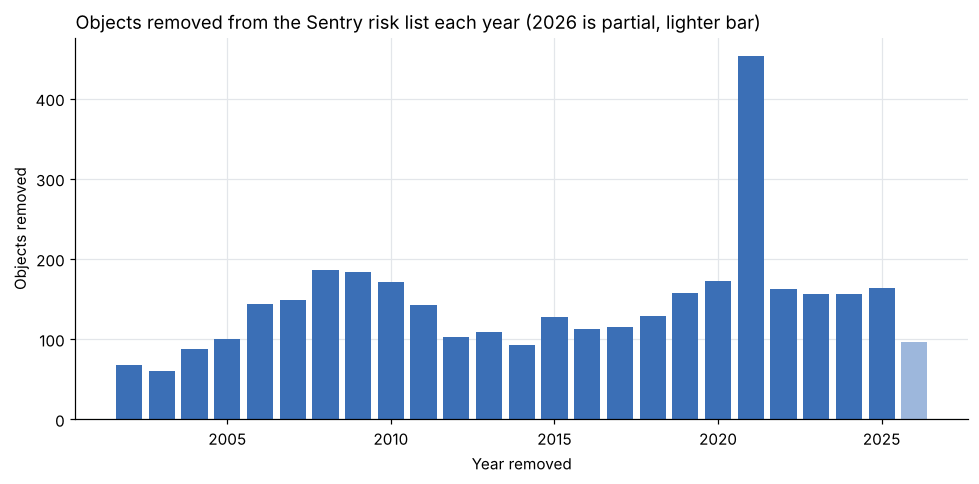

In [4]:
removed = pd.DataFrame(get_json(API + '?removed=1', 'sentry_removed.json')['data'])
removed['removed'] = pd.to_datetime(removed['removed'])
print(f"Objects removed from Sentry since {removed['removed'].min():%Y}: {len(removed):,}")

per_year = removed['removed'].dt.year.value_counts().sort_index()
this_year = pd.Timestamp.now().year
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(per_year.index, per_year.values, color=['#9db7dc' if y == this_year else '#3b6fb6' for y in per_year.index],
       width=0.8)
ax.set_xlabel('Year removed'); ax.set_ylabel('Objects removed')
ax.set_title(f'Objects removed from the Sentry risk list each year ({this_year} is partial, lighter bar)', loc='left')
fig.tight_layout(); fig.savefig(PLOTS / '07_removals_per_year.png', dpi=150); plt.show()

### Time from discovery to removal

An asteroid's provisional name tells you when it was discovered. In **2024 YR4**, "2024" is the year and the first letter, **Y**, is the half-month: A = Jan 1–15, B = Jan 16–31, … Y = Dec 16–31 (the letter I is skipped). So we can estimate how long each object stayed "dangerous" by comparing its discovery half-month with its removal date.

*Caveats:* the discovery date is only known to within about a week, and if an object was removed, re-added and removed again, the list only shows the latest removal. Objects with a permanent number (like 101955 Bennu) don't carry the date in their name and are skipped.

Objects with a dated provisional name: 3,590 of 3,598
Median time on the list: 11 days


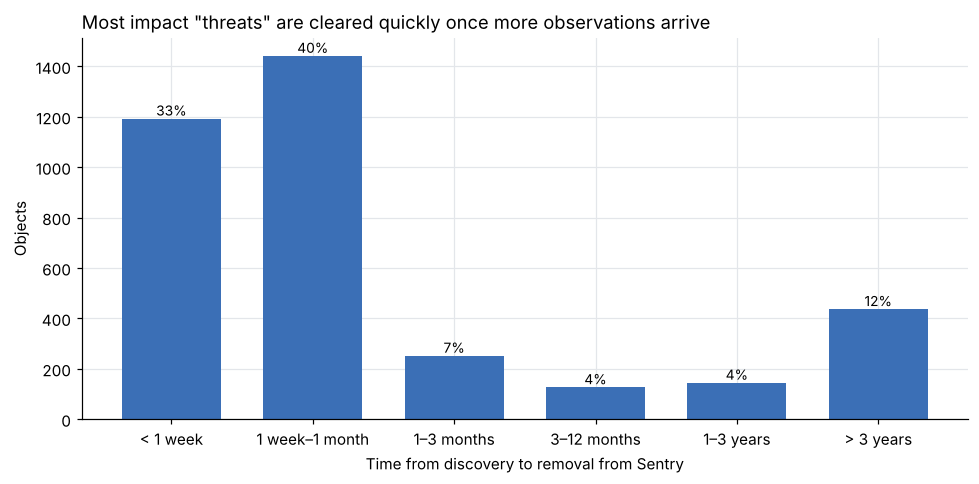

,% of removed objects
days,
< 1 week,33.2
1 week–1 month,40.1
1–3 months,7.0
3–12 months,3.5
1–3 years,4.0
> 3 years,12.1


In [5]:
LETTERS = 'ABCDEFGHJKLMNOPQRSTUVWXY'            # 24 half-months, no I

def discovery_date(des):
    m = re.match(r'^(\d{4}) ([A-HJ-Y])[A-HJ-Z]\d*$', des)
    if not m:
        return pd.NaT
    k = LETTERS.index(m.group(2))
    return pd.Timestamp(int(m.group(1)), k // 2 + 1, 8 if k % 2 == 0 else 23)   # middle of the half-month

removed['discovered'] = removed['des'].map(discovery_date)
r = removed.dropna(subset=['discovered']).copy()
r['days'] = ((r['removed'] - r['discovered']).dt.days).clip(lower=0)
print(f"Objects with a dated provisional name: {len(r):,} of {len(removed):,}")
print(f"Median time on the list: {r['days'].median():.0f} days")

bins   = [0, 7, 30, 90, 365, 3 * 365, 100 * 365]
labels = ['< 1 week', '1 week–1 month', '1–3 months', '3–12 months', '1–3 years', '> 3 years']
counts = pd.cut(r['days'], bins=bins, labels=labels, right=False).value_counts().reindex(labels)
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, counts.values, color='#3b6fb6', width=0.7)
for b, pct in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{pct:.0f}%', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Objects'); ax.set_xlabel('Time from discovery to removal from Sentry')
ax.set_title('Most impact "threats" are cleared quickly once more observations arrive', loc='left')
fig.tight_layout(); fig.savefig(PLOTS / '07_time_to_removal.png', dpi=150); plt.show()
share.round(1).rename('% of removed objects').to_frame()

## 4. Case study: 2024 YR4

The dates below come from NASA announcements and the JWST paper (sources at the end). The removal date is read live from the Sentry API.

Sentry says: specified object removed 2026-03-05 16:02:50


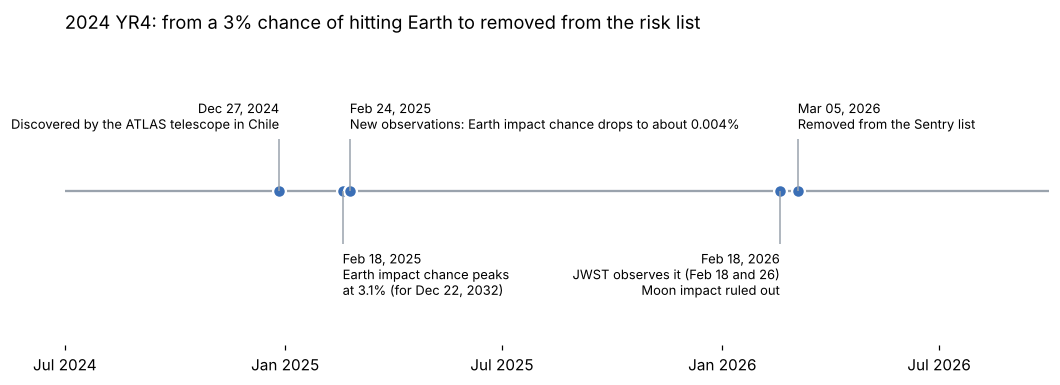

In [6]:
yr4 = get_json(API + '?des=2024%20YR4', 'sentry_2024YR4.json')
removed_date = pd.Timestamp(yr4['removed'])
print('Sentry says:', yr4.get('error'), yr4['removed'])

events = [
    ('2024-12-27', 'Discovered by the ATLAS telescope in Chile'),
    ('2025-02-18', 'Earth impact chance peaks\nat 3.1% (for Dec 22, 2032)'),
    ('2025-02-24', 'New observations: Earth impact chance drops to about 0.004%'),
    ('2026-02-18', 'JWST observes it (Feb 18 and 26)\nMoon impact ruled out'),
    (f'{removed_date:%Y-%m-%d}', 'Removed from the Sentry list'),
]
ev = pd.DataFrame(events, columns=['date', 'event']); ev['date'] = pd.to_datetime(ev['date'])

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axhline(0, color='#9aa3ad', linewidth=1.5, zorder=1)
ax.scatter(ev['date'], [0] * len(ev), s=70, color='#3b6fb6', edgecolor='white', linewidth=1.5, zorder=2)
# label height (+ above, - below) and which side of the line the text sits on, so labels don't overlap
layout = [(1, 'right'), (-1, 'left'), (1, 'left'), (-1, 'right'), (1, 'left')]
for (d, text), (y, side) in zip(zip(ev['date'], ev['event']), layout):
    ax.vlines(d, 0, y * 0.55, color='#9aa3ad', linewidth=1)
    ax.text(d, y * 0.62, f"{d:%b %d, %Y}\n{text}", ha=side, va='bottom' if y > 0 else 'top', fontsize=8.5)
ax.set_ylim(-1.6, 1.6); ax.set_yticks([]); ax.grid(False)
ax.spines[['left', 'bottom']].set_visible(False)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(pd.Timestamp('2024-07-01'), pd.Timestamp('2026-10-01'))
ax.set_title('2024 YR4: from a 3% chance of hitting Earth to removed from the risk list', loc='left')
fig.tight_layout(); fig.savefig(PLOTS / '07_2024YR4_timeline.png', dpi=150); plt.show()

## Takeaways

- **Nothing on the list is more worrying than the normal background risk.** Every object has a Palermo score below 0. The top two, 1950 DA and Bennu, are big (1.3 km and 0.5 km) but their possible impacts are centuries away and unlikely.
- **A high chance doesn't mean high danger.** 2010 RF12 has about a 1-in-10 chance of hitting in 2095, but it's about 7 m across and would burn up in the atmosphere.
- **Most "threats" are temporary.** Of the removed objects with a dated name, about three in four were cleared within a month of discovery, and the median stay on the list was only 11 days. A newly found asteroid's orbit is uncertain; more observations shrink the uncertainty until Earth falls outside it.
- **2024 YR4 is the textbook example.** Its Earth-impact chance rose to 3.1% in February 2025, collapsed a week later, and JWST observations in February 2026 finally ruled out a Moon impact too.

*Numbers in these bullets were read from the outputs above on 2026-11-12. Rerun after deleting the files in `data/` to get the latest list.*

## Data sources

- JPL CNEOS **Sentry** API (risk list and removed objects): https://ssd-api.jpl.nasa.gov/doc/sentry.html
- JPL **Small-Body Database** API (orbits, used by the 3D model in `sentry_3d/`): https://ssd-api.jpl.nasa.gov/doc/sbdb.html
- 2024 YR4 events: NASA Planetary Defense updates (Feb 2025), and de Wit, Rivkin, Micheli, Farnocchia et al., "JWST observations of asteroid 2024 YR4 rule out a 2032 lunar impact", https://arxiv.org/abs/2605.20498
- Minor-planet designation format: IAU Minor Planet Center, https://minorplanetcenter.net/iau/info/OldDesDoc.html